In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score
from xgboost import XGBRegressor

C:\Program Files\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SENSORS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11",
           "s12", "s13", "s14", "s15", "s17", "s20", "s21"]  # the 14 sensors that change
MAX_RUL = 125          # cap for the RUL label
MAINTENANCE_AT = 30    # an engine "needs maintenance" with 30 or fewer cycles left
ALERT_THRESHOLD = 40   # raise an alert when predicted RUL is 40 or less (from the threshold sweep)

In [3]:
cols = ["unit","cycle","op1","op2","op3"] + [f"s{i}" for i in range(1,22)]

In [4]:
train = pd.read_csv("../data/raw/train_FD001.txt", sep = r"\s+", header=None, names = cols)
test = pd.read_csv("../data/raw/test_FD001.txt", sep = r"\s+", header=None, names= cols)
y_test = pd.read_csv("../data/raw/RUL_FD001.txt", sep = r"\s+", header = None).iloc[: , 0].values

In [5]:
test.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [6]:
print(y_test)

[112  98  69  82  91  93  91  95 111  96  97 124  95 107  83  84  50  28
  87  16  57 111 113  20 145 119  66  97  90 115   8  48 106   7  11  19
  21  50 142  28  18  10  59 109 114  47 135  92  21  79 114  29  26  97
 137  15 103  37 114 100  21  54  72  28 128  14  77   8 121  94 118  50
 131 126 113  10  34 107  63  90   8   9 137  58 118  89 116 115 136  28
  38  20  85  55 128 137  82  59 117  20]


In [7]:
train.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [8]:
print(train.shape, test.shape, len(y_test))

(20631, 26) (13096, 26) 100


In [9]:
train.groupby("unit")["cycle"].max().describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [10]:
train.describe().T[["mean","std"]]

,mean,std
unit,51.506568,2.922763e+01
cycle,108.807862,6.888099e+01
op1,-0.000009,2.187313e-03
op2,0.000002,2.930621e-04
op3,100.000000,0.000000e+00
s1,518.670000,0.000000e+00
s2,642.680934,5.000533e-01
s3,1590.523119,6.131150e+00
s4,1408.933782,9.000605e+00
s5,14.620000,5.329200e-15


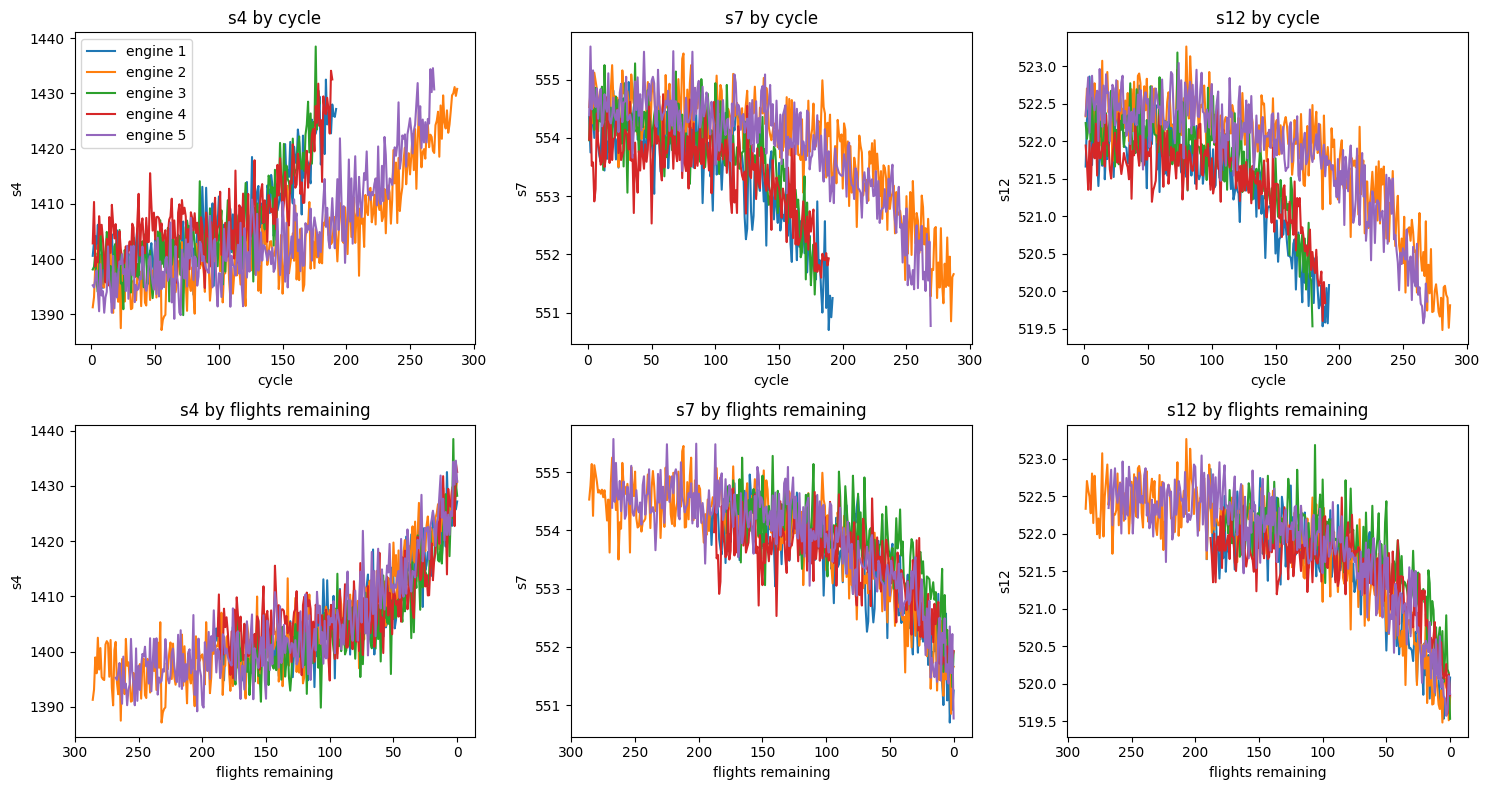

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, s in enumerate(["s4", "s7", "s12"]):
    for unit in range(1, 6):
        d = train[train.unit == unit]
        axes[0, col].plot(d.cycle, d[s], label=f"engine {unit}")
        axes[1, col].plot(d.cycle.max() - d.cycle, d[s], label=f"engine {unit}")
    axes[0, col].set(title=f"{s} by cycle", xlabel="cycle", ylabel=s)
    axes[1, col].set(title=f"{s} by flights remaining", xlabel="flights remaining", ylabel=s)
    axes[1, col].invert_xaxis()
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [12]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

In [13]:
train["RUL"] = train["RUL"].clip(upper = MAX_RUL)

In [14]:
train.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125


In [15]:
def add_features(df, window=10):
    df = df.copy()
    for s in SENSORS:
        grp = df.groupby("unit")[s]
        df[f"{s}_mean"] = grp.transform(lambda x: x.rolling(window, min_periods=1).mean())
        df[f"{s}_std"] = grp.transform(lambda x: x.rolling(window, min_periods=1).std().fillna(0))
    return df

In [16]:
train_f = add_features(train)
test_last = add_features(test).groupby("unit").last()  # one row per test engine: its latest state

FEATURES = SENSORS + [f"{s}_{k}" for s in SENSORS for k in ("mean", "std")]
X, y, groups = train_f[FEATURES], train_f["RUL"], train_f["unit"]
X_test = test_last[FEATURES]

In [17]:
train_f

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s14_mean,s14_std,s15_mean,s15_std,s17_mean,s17_std,s20_mean,s20_std,s21_mean,s21_std
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.620000,0.000000,8.419500,0.000000,392.000000,0.000000,39.060000,0.000000,23.419000,0.000000
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8135.055000,5.041671,8.425650,0.008697,392.000000,0.000000,39.030000,0.042426,23.421300,0.003253
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8134.446667,3.717450,8.423033,0.007640,391.333333,1.154701,39.003333,0.055076,23.395600,0.044573
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8134.292500,3.050906,8.409325,0.028117,391.500000,1.000000,38.972500,0.076322,23.390175,0.037977
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8134.194000,2.651326,8.413340,0.025953,391.800000,1.095445,38.958000,0.073621,23.393020,0.033498
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,8141.170000,1.966554,8.510310,0.023486,396.000000,1.414214,38.453000,0.154923,23.092540,0.077684
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,8140.771000,2.462169,8.510830,0.023504,395.900000,1.449138,38.416000,0.140886,23.085400,0.065961
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,8140.882000,2.445507,8.519150,0.026468,396.200000,1.549193,38.424000,0.139619,23.073210,0.081577
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,8140.833000,2.474775,8.524340,0.024477,396.000000,1.563472,38.388000,0.119889,23.073700,0.081498


In [18]:
test_last

,cycle,op1,op2,op3,s1,s2,s3,s4,s5,s6,...,s14_mean,s14_std,s15_mean,s15_std,s17_mean,s17_std,s20_mean,s20_std,s21_mean,s21_std
unit,,,,,,,,,,,,,,,,,,,,,
1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,21.61,...,8130.849,2.631744,8.42013,0.022340,392.2,0.788811,38.933,0.114120,23.36944,0.026390
2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,21.61,...,8127.584,2.054952,8.44631,0.023850,392.4,0.843274,38.847,0.084859,23.29325,0.049705
3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,21.61,...,8129.387,2.904323,8.46210,0.022946,393.9,0.994429,38.743,0.134002,23.22671,0.039177
4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,21.61,...,8133.675,2.720683,8.45089,0.016581,393.4,1.074968,38.783,0.102637,23.26245,0.054676
5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,21.61,...,8130.344,3.669963,8.45198,0.018150,393.5,0.707107,38.774,0.082219,23.25765,0.078644
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,97,-0.0006,0.0003,100.0,518.67,642.30,1590.88,1397.94,14.62,21.61,...,8148.740,3.332810,8.40661,0.016788,392.1,0.994429,39.006,0.070742,23.38495,0.058493
97,134,0.0013,-0.0001,100.0,518.67,642.59,1582.96,1410.92,14.62,21.61,...,8152.887,3.555434,8.43026,0.025340,393.2,1.135292,38.893,0.155138,23.36623,0.062008
98,121,0.0017,0.0001,100.0,518.67,642.68,1599.51,1415.47,14.62,21.61,...,8140.822,2.644663,8.45775,0.027968,393.7,0.948683,38.779,0.042282,23.31066,0.056840


In [19]:
lr = LinearRegression().fit(train[SENSORS], train["RUL"])

In [20]:
def evaluate(y_true, y_pred):
    d = y_pred - y_true  # positive d = predicted too late
    rmse = np.sqrt(np.mean(d ** 2))
    nasa = np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))
    return round(float(rmse), 2), round(float(nasa), 1)


In [21]:
print("Baseline (RMSE, NASA score):", evaluate(y_test, lr.predict(test_last[SENSORS])))

Baseline (RMSE, NASA score): (21.9, 1314.0)


In [22]:
models = {
    "Random Forest" : RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "XGBoost" : XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,subsample=0.8, colsample_bytree=0.8, random_state=0)
}

for name,model in models.items():
    cv = cross_val_score(model,X,y,groups=groups, cv=GroupKFold(n_splits=5), scoring="neg_root_mean_squared_error")
    model.fit(X,y)
    print(f"{name} | CV RMSE : {round(-cv.mean(),2)} | test (RMSE, NASA) {evaluate(y_test,model.predict(X_test))}")

Random Forest | CV RMSE : 18.73 | test (RMSE, NASA) (21.04, 2294.3)


XGBoost | CV RMSE : 18.28 | test (RMSE, NASA) (19.44, 1226.9)


In [23]:
param_grid = {
    "max_depth": [3, 4, 6],              # how many questions each tree may ask
    "learning_rate": [0.03, 0.05, 0.1],  # how much of each tree's correction is kept
    "n_estimators": [200, 400, 800],     # how many trees
}
search = GridSearchCV(
    XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=0),
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
)
search.fit(X, y, groups=groups)
print(search.best_params_, "| CV RMSE:", round(-search.best_score_, 2))

Fitting 5 folds for each of 27 candidates, totalling 135 fits


{'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200} | CV RMSE: 18.06


In [24]:
best_xgb = search.best_estimator_
print("Tuned XGBoost | CV RMSE:", round(-search.best_score_, 2),
      "| test (RMSE, NASA):", evaluate(y_test, best_xgb.predict(X_test)))


Tuned XGBoost | CV RMSE: 18.06 | test (RMSE, NASA): (19.56, 1259.9)


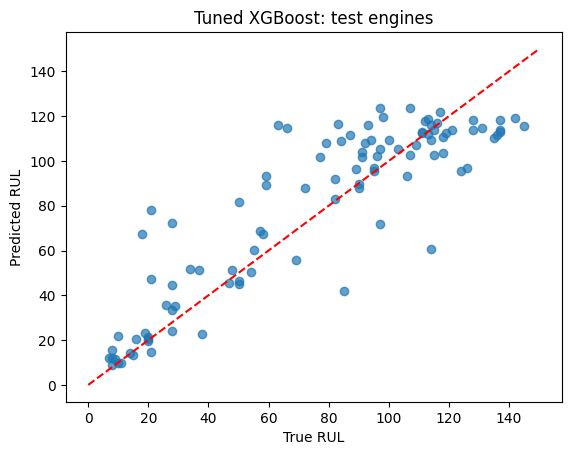

In [25]:
pred = best_xgb.predict(X_test)
plt.scatter(y_test, pred, alpha=0.7)
plt.plot([0, 150], [0, 150], "r--")  # perfect-prediction line
plt.xlabel("True RUL")
plt.ylabel("Predicted RUL")
plt.title("Tuned XGBoost: test engines")
plt.show()

In [26]:
final_models = {
    "Linear (baseline)": (lr, test_last[SENSORS]),
    "Random Forest": (models["Random Forest"], X_test),
    "XGBoost": (models["XGBoost"], X_test),
    "XGBoost (tuned)": (best_xgb, X_test),
}

rows = []
for name, (model, data) in final_models.items():
    pred = model.predict(data)
    rmse, nasa = evaluate(y_test, pred)
    rows.append({
        "model": name,
        "MAE": round(mean_absolute_error(y_test, pred), 2),
        "RMSE": rmse,
        "R2": round(r2_score(y_test, pred), 3),
        "NASA": nasa,
    })

comparison = pd.DataFrame(rows).set_index("model")
comparison


,MAE,RMSE,R2,NASA
model,,,,
Linear (baseline),17.61,21.90,0.722,1314.0
Random Forest,14.67,21.04,0.744,2294.3
XGBoost,13.81,19.44,0.781,1226.9
XGBoost (tuned),14.02,19.56,0.779,1259.9


In [27]:
errors = pd.DataFrame({
    "true_RUL": y_test,
    "pred_RUL": best_xgb.predict(X_test),
}, index=X_test.index)

errors["error"] = errors["pred_RUL"] - errors["true_RUL"]  # + = late (dangerous), - = early (safe)
d = errors["error"]
errors["nasa_penalty"] = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

print("late:", (d > 0).sum(), "| early:", (d < 0).sum())
print("share of NASA score from the 5 worst engines:",
      f"{errors['nasa_penalty'].nlargest(5).sum() / errors['nasa_penalty'].sum():.0%}")
errors.sort_values("nasa_penalty", ascending=False).head(10).round(1)


late: 60 | early: 40
share of NASA score from the 5 worst engines: 67%


,true_RUL,pred_RUL,error,nasa_penalty
unit,,,,
37,21,78.000000,57.0,297.1
79,63,116.000000,53.0,198.6
41,18,67.199997,49.2,136.6
27,66,114.599998,48.6,128.1
18,28,72.300003,44.3,83.0
45,114,60.500000,-53.5,60.1
43,59,93.099998,34.1,29.2
15,83,116.300003,33.3,26.9
93,85,41.900002,-43.1,26.6


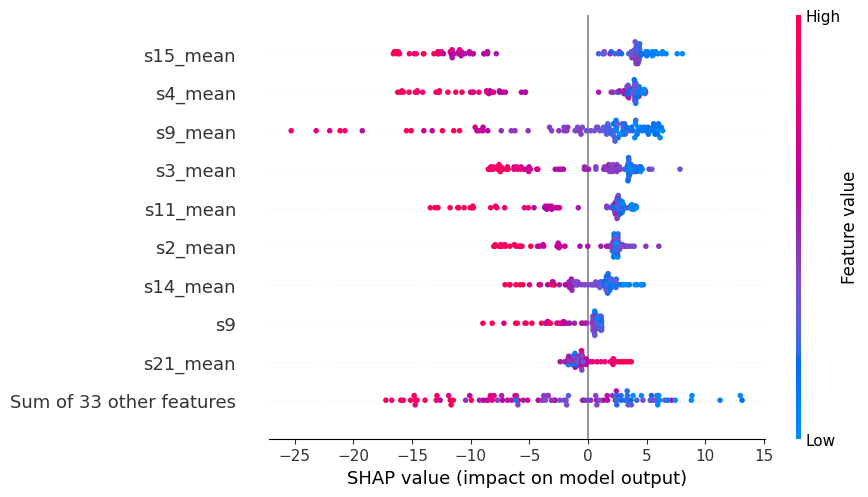

In [28]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test)                  # one row of explanations per test engine
shap.plots.beeswarm(shap_values, max_display=10)

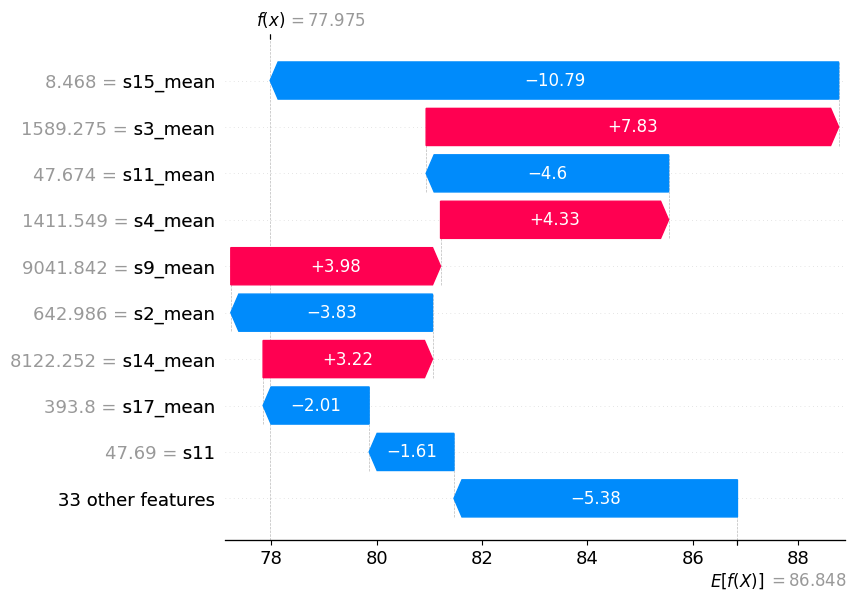

In [29]:
row = X_test.index.get_loc(37)                   # engine 37 is at position 36
shap.plots.waterfall(shap_values[row], max_display=10)


In [30]:
keys = ["s3", "s4", "s9", "s11", "s15"]
def drift(df):
    """Change from each engine's first 10 cycles to its last 10."""
    return df.groupby("unit")[keys].apply(lambda x: x.tail(10).mean() - x.head(10).mean())

pd.DataFrame({"engine 37": drift(test).loc[37],
              "typical engine at failure": drift(train).median()}).round(2)


,engine 37,typical engine at failure
s3,4.14,14.60
s4,11.70,24.80
s9,-12.55,20.32
s11,0.48,0.74
s15,0.07,0.10


In [31]:
errors["needs_maintenance"] = errors["true_RUL"] <= MAINTENANCE_AT   # the truth
errors["alert"] = errors["pred_RUL"] <= MAINTENANCE_AT               # what the model says

pd.crosstab(errors["needs_maintenance"], errors["alert"],
            rownames=["needs maintenance"], colnames=["alert raised"])

alert raised,False,True
needs maintenance,,
False,74,1
True,8,17


In [32]:
need = errors["needs_maintenance"]
for t in [30, 40, 50, 60]:
    alert = errors["pred_RUL"] <= t
    print(f"alert at {t}: caught {(alert & need).sum()}/{need.sum()}, "
          f"false alarms {(alert & ~need).sum()}")

alert at 30: caught 17/25, false alarms 1
alert at 40: caught 20/25, false alarms 1
alert at 50: caught 22/25, false alarms 5
alert at 60: caught 22/25, false alarms 10


In [33]:
bins = [-np.inf, 30, 60, np.inf]
labels = ["Critical", "Warning", "Healthy"]

errors["health"] = pd.cut(errors["pred_RUL"], bins=bins, labels=labels)
errors["true_health"] = pd.cut(errors["true_RUL"], bins=bins, labels=labels)

pd.crosstab(errors["true_health"], errors["health"],
            rownames=["true band"], colnames=["predicted band"])

predicted band,Critical,Warning,Healthy
true band,,,
Critical,17,5,3
Warning,1,7,6
Healthy,0,2,59


## From notebook to pipeline

This notebook is the research record. The production version of the same steps lives in `src/turbofan_rul/`:
`python -m turbofan_rul.train` re-runs the baselines and the grid search, logs everything to MLflow, registers the model and exports it to `models/` for the API. It reproduces the numbers above (CV 18.06, test RMSE 19.56).